# Random Forest with wind speed and wind history

Does the RF close the gap with the U-Net if it gets the same information in time?

All variants: same split (train Jan–Aug, validation Sep, test Oct–Dec), same 600k training rows
(sampled from Jan–Aug ocean cells), same hyperparameters as the original notebook.

| Variant | Inputs |
|---|---|
| A. original | Lat, Lon, u10, v10, MSLP |
| B. + wind speed | A + wind speed √(u10² + v10²) |
| C. + wind history | Lat, Lon + u10, v10, wind speed, MSLP at 0, 1, 3, 6, 12, 24 h before (same as the U-Net) |

The only difference left between C and the U-Net is spatial context: the RF sees one cell, the U-Net the whole map.

The first cells are the setup cells of `iEMs_UNet.ipynb` (data loading), unchanged.

In [1]:
from __future__ import annotations

import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# -----------------------------
# USER SETTINGS
# -----------------------------
# Data: read X_2005.txt / Y_2005.txt from DATA_DIR if present, otherwise straight from the zip.
DATA_DIR = Path("../../Copy of Dataset and code - Wave Power")
ZIP_PATH = Path("../../Copy of Dataset and code - Wave Power.zip")
X_NAME, Y_NAME = "X_2005.txt", "Y_2005.txt"

OUTDIR = Path("unet_2005_outputs")
OUTDIR.mkdir(exist_ok=True, parents=True)
GRID_CACHE = OUTDIR / "grids_2005.npz"   # parsed (time, lat, lon) arrays; delete to re-parse

RANDOM_SEED = 42

# Chronological split, as [start, end) hour indices (2005 is hourly: 8760 steps)
TRAIN_HOURS = (0, 243 * 24)          # 1 Jan – 31 Aug
VAL_HOURS   = (243 * 24, 273 * 24)   # September (early stopping / LR schedule)
TEST_HOURS  = (273 * 24, 365 * 24)   # 1 Oct – 31 Dec

# Wind/pressure history fed to the network: fields at t - lag for each lag (hours).
# Waves respond to wind over the previous hours, and swell arrives from upwind.
LAGS = [0, 1, 3, 6, 12, 24]

# U-Net
BASE_CHANNELS = 32
DEPTH = 3            # number of 2x downsamplings; the grid is zero-padded to a multiple of 2**DEPTH
DROPOUT = 0.1        # also used for the MC-dropout uncertainty band

# Training
BATCH_SIZE = 32
EPOCHS = 40
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 8         # early stopping on validation RMSE

# Plot settings
MC_SAMPLES = 20
PLOT_SUBSAMPLE = 60_000
CI_BINS = 80
ADD_PM10_ENVELOPE = True

PAIRS_OUT = OUTDIR / "actual_vs_predicted_test_sample.txt"
PAIRS_SEP = "\t"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Device:", DEVICE)

Device: cuda


In [3]:
# -----------------------------
# LOAD ROWS -> (time, lat, lon) GRIDS
# -----------------------------
def open_source(name: str):
    p = DATA_DIR / name
    if p.exists():
        return open(p, "rb")
    return zipfile.ZipFile(ZIP_PATH).open(name)


def load_grids() -> dict:
    if GRID_CACHE.exists():
        with np.load(GRID_CACHE) as d:
            return {k: d[k] for k in d.files}

    print("Parsing text files (one-off, cached afterwards)...")
    with open_source(X_NAME) as f:
        X = pd.read_csv(f, header=None, usecols=range(5), dtype=np.float32).to_numpy()
    with open_source(Y_NAME) as f:
        y = pd.read_csv(f, header=None, usecols=[0], dtype=np.float32).to_numpy()[:, 0]
    if len(X) != len(y):
        raise ValueError(f"X has {len(X)} rows but Y has {len(y)}")

    lat_vals = np.unique(X[:, 0])
    lon_vals = np.unique(X[:, 1])
    nlat, nlon = len(lat_vals), len(lon_vals)
    ncell = nlat * nlon
    if len(X) % ncell:
        raise ValueError(f"{len(X)} rows is not a whole number of {nlat}x{nlon} grids")
    nt = len(X) // ncell

    # rows come as consecutive blocks of one full grid per hour
    t = np.arange(len(X)) // ncell
    ilat = np.searchsorted(lat_vals, X[:, 0])
    ilon = np.searchsorted(lon_vals, X[:, 1])
    counts = np.bincount((t * nlat + ilat) * nlon + ilon, minlength=nt * ncell)
    if not (counts == 1).all():
        raise ValueError("Rows are not one-per-cell-per-hour blocks; cannot reshape to grids.")

    fields = np.full((nt, 3, nlat, nlon), np.nan, dtype=np.float32)   # u10, v10, MSLP
    fields[t, :, ilat, ilon] = X[:, 2:5]
    hm0 = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
    hm0[t, ilat, ilon] = y

    grids = dict(fields=fields, hm0=hm0, lat=lat_vals, lon=lon_vals)
    np.savez(GRID_CACHE, **grids)
    return grids


grids = load_grids()
NT, NLAT, NLON = grids["hm0"].shape
OCEAN = np.isfinite(grids["hm0"]).all(axis=0)   # cells with Hm0 at every hour
LAT, LON = grids["lat"], grids["lon"]
print(f"{NT} hours x {NLAT} lat x {NLON} lon; ocean cells: {OCEAN.sum()} / {OCEAN.size}")
print(f"Lat {LAT.min()}..{LAT.max()}, Lon {LON.min()}..{LON.max()}")
assert TEST_HOURS[1] <= NT, "TEST_HOURS goes past the end of the data"

8760 hours x 29 lat x 45 lon; ocean cells: 967 / 1305
Lat 50.0..57.0, Lon -15.0..-4.0


In [4]:
# -----------------------------
# FEATURES PER (hour, ocean cell)
# -----------------------------
from sklearn.ensemble import RandomForestRegressor

RES_DIR = Path("../../results/3_comparison")
RES_DIR.mkdir(exist_ok=True, parents=True)

ocean_i, ocean_j = np.nonzero(OCEAN)
NC = len(ocean_i)
U, V, P = (grids["fields"][:, k][:, ocean_i, ocean_j] for k in range(3))   # (T, cells)
WS = np.hypot(U, V)
HM0 = grids["hm0"][:, ocean_i, ocean_j]


def features(t, c, variant):
    # rows for hour indices t and ocean-cell indices c (same length)
    lat, lon = LAT[ocean_i[c]], LON[ocean_j[c]]
    if variant == "A":
        cols = [lat, lon, U[t, c], V[t, c], P[t, c]]
    elif variant == "B":
        cols = [lat, lon, U[t, c], V[t, c], P[t, c], WS[t, c]]
    else:
        cols = [lat, lon]
        for L in LAGS:
            tl = np.clip(t - L, 0, None)   # first hours of the year: repeat hour 0
            cols += [U[tl, c], V[tl, c], WS[tl, c], P[tl, c]]
    return np.column_stack(cols).astype(np.float32)


NAMES = {
    "A": ["Lat", "Lon", "u10", "v10", "MSLP"],
    "B": ["Lat", "Lon", "u10", "v10", "MSLP", "wind_speed"],
    "C": ["Lat", "Lon"] + [f"{v}_lag{L}h" for L in LAGS for v in ["u10", "v10", "wind_speed", "MSLP"]],
}
LABEL = {"A": "RF A: original inputs", "B": "RF B: + wind speed", "C": "RF C: + wind speed + wind history"}


def all_rows(hours):
    t = np.repeat(hours, NC)
    c = np.tile(np.arange(NC), len(hours))
    return t, c


# same 600k training rows as the earlier comparison (Jan-Aug ocean rows, seed 42)
t_all, c_all = all_rows(np.arange(*TRAIN_HOURS))
sel = np.random.default_rng(RANDOM_SEED).choice(len(t_all), 600_000, replace=False)
t_tr, c_tr = t_all[sel], c_all[sel]
splits = {
    "train (600k rows)": (t_tr, c_tr),
    "validation (Sep)": all_rows(np.arange(*VAL_HOURS)),
    "test (Oct-Dec)": all_rows(np.arange(*TEST_HOURS)),
}
print({k: len(v[0]) for k, v in splits.items()})

{'train (600k rows)': 600000, 'validation (Sep)': 696240, 'test (Oct-Dec)': 2135136}


In [5]:
# -----------------------------
# TRAIN + EVALUATE THE THREE VARIANTS
# -----------------------------
def scores(y, p):
    return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** 0.5, R2=r2_score(y, p))


rows, importances, models = [], {}, {}
for variant in ["A", "B", "C"]:
    t0 = time.time()
    rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1,
                               min_samples_leaf=5, max_features="sqrt")
    rf.fit(features(t_tr, c_tr, variant), HM0[t_tr, c_tr])
    for split, (t, c) in splits.items():
        p = np.concatenate([rf.predict(features(t[i:i + 500_000], c[i:i + 500_000], variant))
                            for i in range(0, len(t), 500_000)])
        rows.append({"model": LABEL[variant], "split": split, **scores(HM0[t, c], p)})
    importances[variant] = pd.Series(rf.feature_importances_, index=NAMES[variant]).sort_values(ascending=False)
    print(f"{LABEL[variant]}: {time.time() - t0:.0f}s")
    models[variant] = rf

res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))

RF A: original inputs: 145s


RF B: + wind speed: 139s


RF C: + wind speed + wind history: 195s
                            model             split   MAE  RMSE    R2
            RF A: original inputs train (600k rows) 0.246 0.388 0.938
            RF A: original inputs  validation (Sep) 0.552 0.747 0.715
            RF A: original inputs    test (Oct-Dec) 0.658 0.876 0.675
               RF B: + wind speed train (600k rows) 0.254 0.399 0.935
               RF B: + wind speed  validation (Sep) 0.545 0.739 0.722
               RF B: + wind speed    test (Oct-Dec) 0.635 0.849 0.694
RF C: + wind speed + wind history train (600k rows) 0.081 0.137 0.992
RF C: + wind speed + wind history  validation (Sep) 0.382 0.525 0.860
RF C: + wind speed + wind history    test (Oct-Dec) 0.456 0.609 0.843


In [6]:
# -----------------------------
# ONE TABLE: RF variants + U-Net (same split)
# -----------------------------
wide = res.pivot(index="model", columns="split", values=["MAE", "RMSE", "R2"])
wide = wide.reindex(columns=["train (600k rows)", "validation (Sep)", "test (Oct-Dec)"], level=1)
wide.columns = [f"{s.split(' ')[0].capitalize()} {m}" for m, s in wide.columns]
wide = wide[[f"{s} {m}" for s in ["Train", "Validation", "Test"] for m in ["MAE", "RMSE", "R2"]]]

# U-Net numbers from the earlier comparison (same split; 3 epochs, best validation checkpoint)
unet = pd.read_csv(RES_DIR / "chronological_split_3_epochs.csv").query("model == 'U-Net'").set_index("split")
wide.loc["U-Net (3 epochs)"] = [unet.loc[s, m] for s in ["train (Jan-Aug)", "validation (Sep)", "test (Oct-Dec)"]
                                for m in ["MAE", "RMSE", "R2"]]
wide = wide.reindex([LABEL["A"], LABEL["B"], LABEL["C"], "U-Net (3 epochs)"])
wide.round(3).to_csv(RES_DIR / "rf_with_wind_features.csv")
print(wide.round(3).to_string())

                                   Train MAE  Train RMSE  Train R2  Validation MAE  Validation RMSE  Validation R2  Test MAE  Test RMSE  Test R2
model                                                                                                                                           
RF A: original inputs                  0.246       0.388     0.938           0.552            0.747          0.715     0.658      0.876    0.675
RF B: + wind speed                     0.254       0.399     0.935           0.545            0.739          0.722     0.635      0.849    0.694
RF C: + wind speed + wind history      0.081       0.137     0.992           0.382            0.525          0.860     0.456      0.609    0.843
U-Net (3 epochs)                       0.372       0.550     0.874           0.356            0.478          0.883     0.452      0.603    0.846


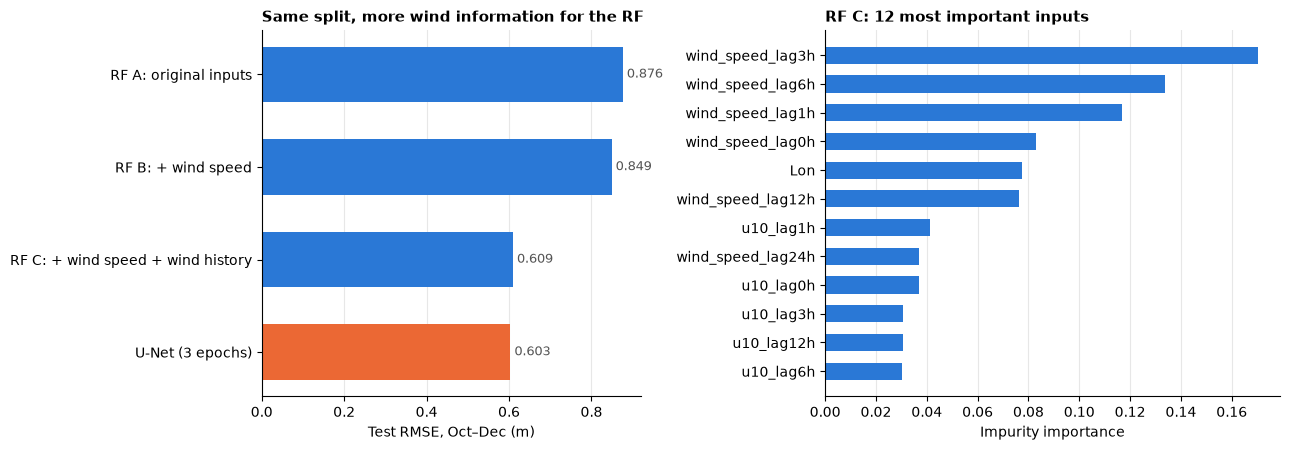

In [7]:
# -----------------------------
# TEST RMSE CHART + RF C IMPORTANCES
# -----------------------------
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})

ax = axes[0]
names = list(wide.index)
vals = wide["Test RMSE"].to_numpy()
cols = ["#2a78d6"] * 3 + ["#eb6834"]
bars = ax.barh(names[::-1], vals[::-1], color=cols[::-1], height=0.6)
for b, val in zip(bars, vals[::-1]):
    ax.text(val + 0.01, b.get_y() + b.get_height() / 2, f"{val:.3f}", va="center", fontsize=9, color="#555")
ax.set_xlabel("Test RMSE, Oct–Dec (m)")
ax.set_title("Same split, more wind information for the RF", loc="left", fontweight="bold", fontsize=11)
ax.grid(axis="y", visible=False)

ax = axes[1]
top = importances["C"].head(12)[::-1]
ax.barh(top.index, top.values, color="#2a78d6", height=0.6)
ax.set_xlabel("Impurity importance")
ax.set_title("RF C: 12 most important inputs", loc="left", fontweight="bold", fontsize=11)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(RES_DIR / "plots" / "rf_with_wind_features.png", dpi=300)
plt.show()

for v in "ABC":
    importances[v].rename("importance").to_csv(RES_DIR / f"rf_{v}_feature_importance.csv")

In [8]:
# -----------------------------
# SHAP FOR RF C (exact Shapley values over groups of inputs)
# -----------------------------
# Same explained points and background as iEMs_SHAP.ipynb (same seed and draw order):
# 20 ocean cells x 100 Oct-Dec hours, 100 Jan-Aug background rows.
from itertools import combinations
from math import factorial

SHAP_DIR = Path("../../results/4_shap")
shap_rng = np.random.default_rng(RANDOM_SEED)
test_t = np.arange(max(TEST_HOURS[0], max(LAGS)), TEST_HOURS[1])
train_t = np.arange(max(TRAIN_HOURS[0], max(LAGS)), TRAIN_HOURS[1])
explain_times = np.sort(shap_rng.choice(test_t, 100, replace=False))
_ = shap_rng.choice(train_t, 100, replace=False)          # U-Net background maps (not needed here)
pix = shap_rng.choice(NC, 20, replace=False)
bg_idx = shap_rng.choice(len(t_all), 100, replace=False)  # RF background rows (Jan-Aug)

t_ex, c_ex = np.repeat(explain_times, len(pix)), np.tile(pix, len(explain_times))
X_ex = features(t_ex, c_ex, "C")
X_bg = features(t_all[bg_idx], c_all[bg_idx], "C")
rfC = models["C"]


def group_shap(model, X_ex, X_bg, groups):
    # Exact interventional Shapley values for groups of columns: (points, groups)
    G, n, B, F = len(groups), len(X_ex), len(X_bg), X_ex.shape[1]
    value = {}
    for mask in range(2 ** G):
        cols = [c for g in range(G) if mask >> g & 1 for c in groups[g]]
        X = np.repeat(X_bg[None], n, axis=0)
        if cols:
            X[:, :, cols] = X_ex[:, None, cols]
        value[mask] = model.predict(X.reshape(-1, F)).reshape(n, B).mean(1)
    phi = np.zeros((n, G))
    for g in range(G):
        for mask in range(2 ** G):
            if mask >> g & 1:
                continue
            s = bin(mask).count("1")
            phi[:, g] += factorial(s) * factorial(G - s - 1) / factorial(G) * (value[mask | 1 << g] - value[mask])
    return phi, value[0]


names_C = NAMES["C"]
idx = lambda pred: [i for i, n in enumerate(names_C) if pred(n)]
groups_var = {"u10": idx(lambda n: n.startswith("u10_")), "v10": idx(lambda n: n.startswith("v10_")),
              "wind_speed": idx(lambda n: n.startswith("wind_speed_")), "MSLP": idx(lambda n: n.startswith("MSLP_")),
              "Lat": [0], "Lon": [1]}
groups_lag = {f"{L} h": idx(lambda n, L=L: n.endswith(f"_lag{L}h")) for L in LAGS}
groups_lag.update({"Lat": [0], "Lon": [1]})

t0 = time.time()
phi_var, base = group_shap(rfC, X_ex, X_bg, list(groups_var.values()))
phi_lag, _ = group_shap(rfC, X_ex, X_bg, list(groups_lag.values()))
pred = rfC.predict(X_ex)
print(f"RF C SHAP done in {time.time() - t0:.0f}s; additivity error max = {np.abs(phi_var.sum(1) + base - pred).max():.1e}")

rfC_var = pd.Series(np.abs(phi_var).mean(0), index=list(groups_var))
rfC_lag = pd.Series(np.abs(phi_lag).mean(0), index=list(groups_lag))
rfC_var.rename("mean_abs_SHAP_m").to_csv(SHAP_DIR / "rf_wind_history_shap_by_variable.csv")
rfC_lag.rename("mean_abs_SHAP_m").to_csv(SHAP_DIR / "rf_wind_history_shap_by_lag.csv")
print(rfC_var.round(3).to_string()); print(rfC_lag.round(3).to_string())

RF C SHAP done in 176s; additivity error max = 5.3e-15
u10           0.267
v10           0.103
wind_speed    0.739
MSLP          0.162
Lat           0.027
Lon           0.265
0 h     0.168
1 h     0.190
3 h     0.212
6 h     0.179
12 h    0.186
24 h    0.199
Lat     0.025
Lon     0.270


            RF original  RF + wind history  U-Net
u10                37.7               17.1   15.0
v10                27.4                6.6    7.6
wind_speed          NaN               47.3   64.6
MSLP               12.6               10.4   12.7
Lat                 4.9                1.7    NaN
Lon                17.4               17.0    NaN


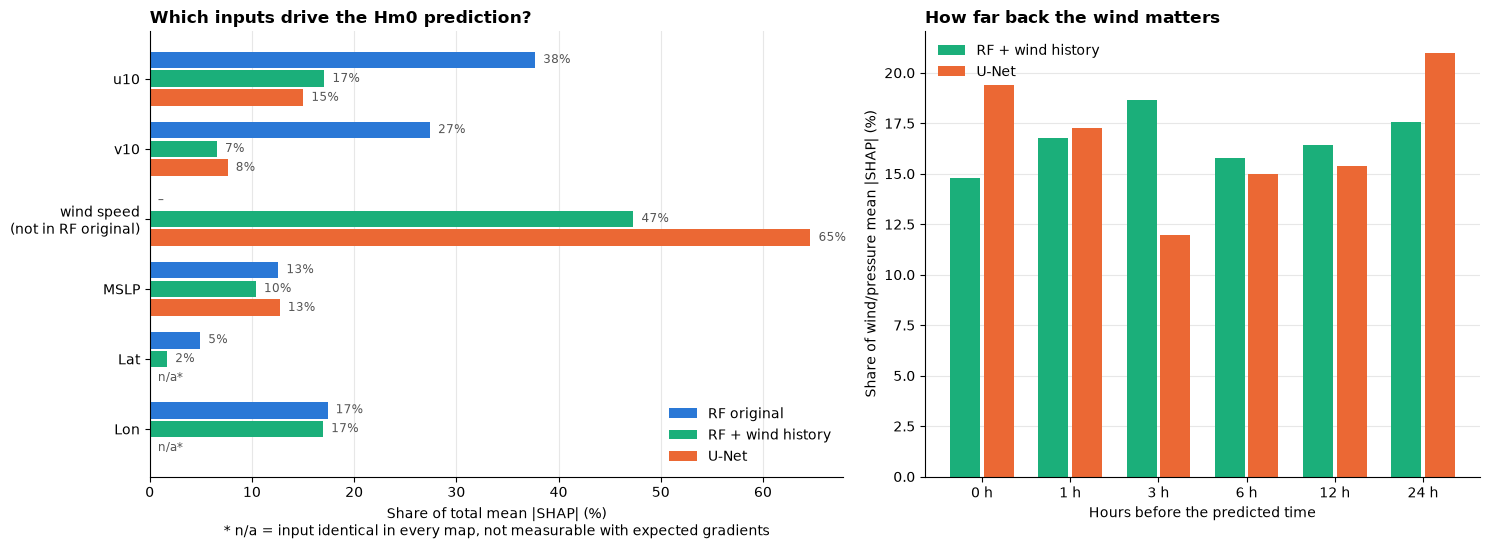

In [9]:
# -----------------------------
# UPDATED SHAP COMPARISON: RF original vs RF + wind history vs U-Net
# -----------------------------
rfA = pd.read_csv(SHAP_DIR / "rf_shap_by_feature.csv", index_col=0).iloc[:, 0]
unet_var = pd.read_csv(SHAP_DIR / "unet_shap_by_variable.csv", index_col=0).iloc[:, 0]
unet_lag = pd.read_csv(SHAP_DIR / "unet_shap_by_lag.csv", index_col=0).iloc[:, 0]

MODELS = {"RF + wind history": rfC_var, "U-Net": unet_var}
COLOR = {"U-Net": "#eb6834", "RF + wind history": "#1baf7a"}   # same colours as the other SHAP plots
order = ["u10", "v10", "wind_speed", "MSLP", "Lat", "Lon"]
share = pd.DataFrame({m: 100 * s.reindex(order) / s.reindex(order).sum() for m, s in MODELS.items()})
share.loc[["Lat", "Lon"], "U-Net"] = np.nan          # not measurable for the U-Net (static inputs)
share.round(1).to_csv(SHAP_DIR / "shap_comparison_all_models.csv")
print(share.round(1).to_string())

lag_order = [f"{L} h" for L in LAGS]
lag_share = pd.DataFrame({"RF + wind history": 100 * rfC_lag[lag_order] / rfC_lag[lag_order].sum(),
                          "U-Net": 100 * unet_lag[lag_order] / unet_lag[lag_order].sum()})
lag_share.round(1).to_csv(SHAP_DIR / "shap_by_lag_rf_vs_unet.csv")

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
labels = {"u10": "u10", "v10": "v10", "wind_speed": "wind speed", "MSLP": "MSLP",
          "Lat": "Lat", "Lon": "Lon"}
y = np.arange(len(order))
h = 0.38
for k, m in enumerate(MODELS):
    vals = share[m].to_numpy()
    off = (k - (len(MODELS) - 1) / 2) * h
    bars = ax.barh(y + off, np.nan_to_num(vals), height=h - 0.03, color=COLOR[m], label=m)
    for b, val, feat in zip(bars, vals, order):
        txt = "n/a*" if np.isnan(val) else f"{val:.0f}%"
        ax.text(np.nan_to_num(val) + 0.8, b.get_y() + b.get_height() / 2, txt, va="center", fontsize=8.5, color="#555")
ax.set_yticks(y, [labels[o] for o in order])
ax.invert_yaxis()
ax.set_xlabel("Share of total mean |SHAP| (%)\n* n/a = input identical in every map, not measurable with expected gradients")
ax.set_title("Which inputs drive the Hm0 prediction?", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")

ax = axes[1]
x = np.arange(len(lag_order))
w = 0.38
for off, m in [(-w / 2, "RF + wind history"), (w / 2, "U-Net")]:
    ax.bar(x + off, lag_share[m], width=w - 0.04, color=COLOR[m], label=m)
ax.set_xticks(x, lag_order)
ax.set_xlabel("Hours before the predicted time")
ax.set_ylabel("Share of wind/pressure mean |SHAP| (%)")
ax.set_title("How far back the wind matters", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(SHAP_DIR / "shap_comparison_all_models.png", dpi=300)
plt.show()